# `pylbsr.bio.rna_plot`: secondary structures on a flat backbone

The exterior loop is drawn as a straight 5'→3' backbone, and every helix stands on it.
Each helix subtree is laid out by ViennaRNA and placed on the backbone; the cursor moves past the
full width of each subtree, so neighbouring helices never overlap.

Install: `pip install "pylbsr[rna]"` (or ViennaRNA from bioconda).

Contents:

1. Minimal call
2. Pairing-probability colouring (tRNA-Phe)
3. Annotations: focus span, loop motifs, tracks, highlighted nucleotides, numbering
4. A constraint structure: which constrained pairs the fold forms
5. Covariation colouring from an alignment
6. Large structures: layout engines and checks
7. Wild type vs mutant, side by side

In [1]:
import random

import matplotlib.pyplot as plt
import RNA

from pylbsr.bio import rna_plot as rp

print("ViennaRNA", RNA.__version__)

ViennaRNA 2.6.4


## 1. Minimal call

Input: a sequence and a dot-bracket string of the same length.
All positions in the API are 0-based; spans are half-open `[start, end)`.

((((((....))))))...((((((....)))))).. -24.200000762939453


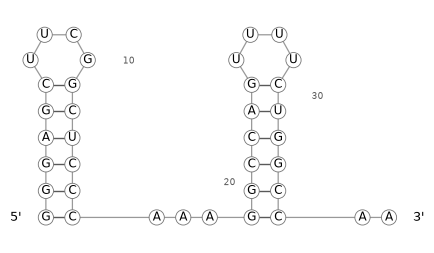

In [2]:
seq = "GGGAGCUUCGGCUCCCAAAGGCCAGUUUUCUGGCCAA"
db, mfe = RNA.fold(seq)
print(db, mfe)

fig, ax = plt.subplots(figsize=rp.suggest_figsize(rp.flat_coordinates(db)))
rp.draw_structure(ax, seq, db)
plt.show()

## 2. Pairing-probability colouring

RNAfold web-server convention: a paired nucleotide shows the probability of *its drawn pair*,
an unpaired one its probability of being unpaired.
Example: yeast tRNA-Phe; its MFE is the cloverleaf.

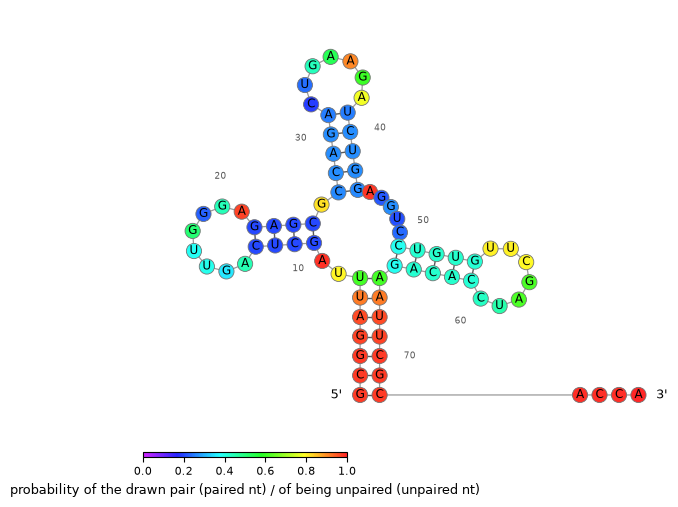

In [3]:
TRNA = "GCGGAUUUAGCUCAGUUGGGAGAGCGCCAGACUGAAGAUCUGGAGGUCCUGUGUUCGAUCCACAGAAUUCGCACCA"
trna_db, _ = RNA.fold(TRNA)
p = rp.pairing_probability(TRNA, trna_db)

fig, ax = plt.subplots(figsize=rp.suggest_figsize(rp.flat_coordinates(trna_db)))
rp.draw_structure(ax, TRNA, trna_db, node_colors=rp.probability_colors(p))
rp.probability_colorbar(fig, ax)
plt.show()

## 3. Annotations

- `focus=(start, end)`: nucleotides outside the span are drawn as flank (grey, dashed outline).
- `loops`: `Loop(start, end, label, color)`; the loop is circled, and its closing pair is drawn
  as squares when it is formed. `hairpin_loops(db, sizes=...)` finds hairpin loops.
- `tracks`: `Track(start, end, label, color, layer)`, e.g. binding sites. Lines run on the
  left of the 5'→3' direction, so they never cross the backbone. One `layer` per track kind.
- `highlight`: positions with a red outline (e.g. a mutation).
- `numbering`: number of the first nucleotide, or one label per nucleotide.

The tracks below are arbitrary spans, for illustration only.

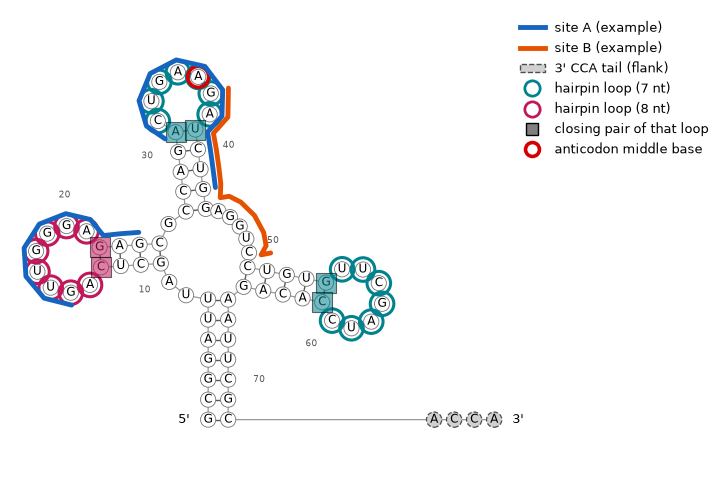

In [4]:
loops = [rp.Loop(s, e, "hairpin loop (7 nt)", "#00838f") for s, e in rp.hairpin_loops(trna_db, [7])]
loops += [rp.Loop(s, e, "hairpin loop (8 nt)", "#c2185b") for s, e in rp.hairpin_loops(trna_db, [8])]
tracks = [
    rp.Track(14, 24, "site A (example)", "#1565c0", layer=0),
    rp.Track(30, 42, "site A (example)", "#1565c0", layer=0),
    rp.Track(36, 50, "site B (example)", "#e65100", layer=1),
]
fig, ax = plt.subplots(figsize=rp.suggest_figsize(rp.flat_coordinates(trna_db)))
res = rp.draw_structure(
    ax,
    TRNA,
    trna_db,
    focus=(0, 72),
    flank_label="3' CCA tail (flank)",
    loops=loops,
    tracks=tracks,
    highlight=[35],
    highlight_label="anticodon middle base",
    numbering=1,
)
ax.legend(handles=res.handles, loc="upper left", bbox_to_anchor=(1, 1), frameon=False, fontsize=9)
plt.show()

## 4. A constraint structure

`constraint` takes a dot-bracket of constrained pairs (e.g. the consensus pairs that guided a
comparative fold). Formed constrained pairs are thick green; constrained pairs that the fold did
not form are dashed.
Here: a mutant that breaks the anticodon stem, drawn against the wild-type cloverleaf.

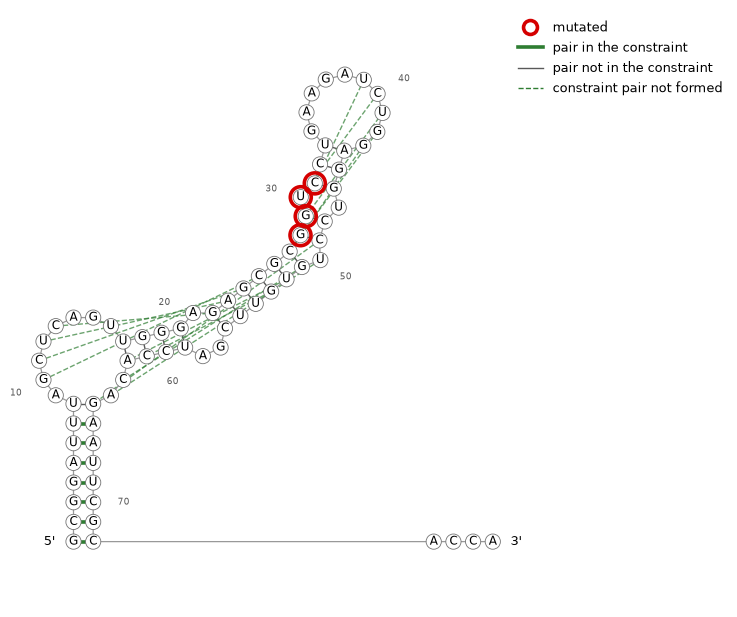

In [5]:
mut = TRNA[:27] + "GGUC" + TRNA[31:]  # anticodon-stem 5' strand replaced
mut_db, _ = RNA.fold(mut)
fig, ax = plt.subplots(figsize=rp.suggest_figsize(rp.flat_coordinates(mut_db)))
res = rp.draw_structure(
    ax, mut, mut_db, constraint=trna_db, highlight=range(27, 31), highlight_label="mutated"
)
ax.legend(handles=res.handles, loc="upper left", bbox_to_anchor=(1, 1), frameon=False, fontsize=9)
plt.show()

## 5. Covariation colouring

RNAalifold `alirna.ps` convention: both partners of a pair get the pair's colour.
Hue = number of distinct canonical pair types across the alignment; paler = more sequences that
cannot form the pair.
The alignment below is **synthetic** (compensatory changes added to tRNA-Phe), for illustration.

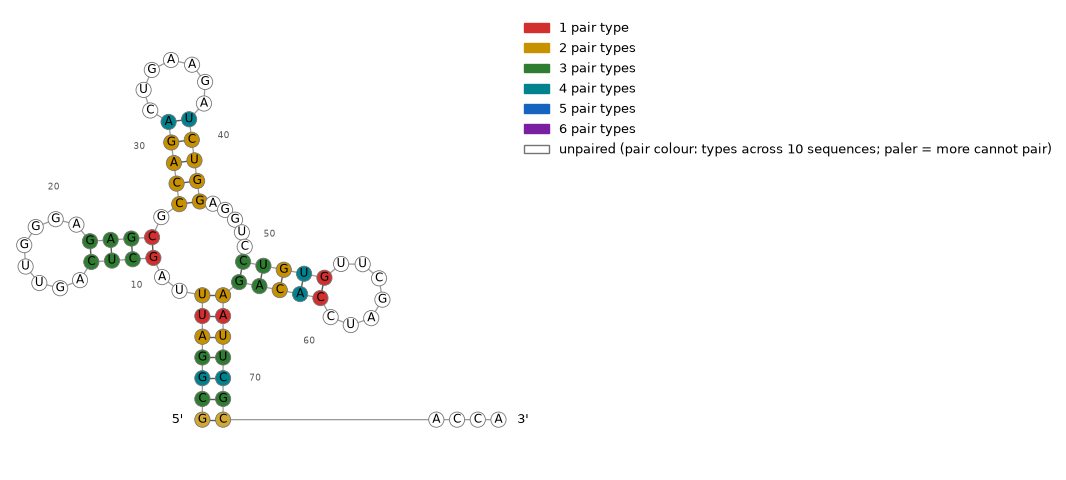

In [6]:
def swap_pair(s, i, j, a, b):
    chars = list(s)
    chars[i], chars[j] = a, b
    return "".join(chars)


pairs = rp.pair_list(trna_db)
rng = random.Random(0)
alignment = {"ref": TRNA}
for k in range(8):
    s = TRNA
    for i, j in rng.sample(pairs, 6):
        a, b = rng.choice(["GC", "CG", "AU", "UA", "GU"])
        s = swap_pair(s, i, j, a, b)
    alignment[f"seq{k}"] = s
alignment["broken"] = swap_pair(TRNA, 0, 71, "A", "A")  # one row that cannot pair (0, 71)

colors = rp.covariation_colors(trna_db, alignment, reference=TRNA)
fig, ax = plt.subplots(figsize=rp.suggest_figsize(rp.flat_coordinates(trna_db)))
rp.draw_structure(ax, TRNA, trna_db, node_colors=colors)
ax.legend(
    handles=rp.covariation_handles(len(alignment)),
    loc="upper left",
    bbox_to_anchor=(1.0, 1.0),
    frameon=False,
    fontsize=9,
)
plt.show()

## 6. Large structures

`engine="auto"` (default) lays out each helix subtree with naview, and falls back to the radial
layout, then to RNApuzzler, while two nucleotides are closer than `min_dist` (0.6 backbone steps).
`min_distance` and `segment_crossings` check a layout.

In [7]:
rng = random.Random(0)
big = "".join(rng.choice("ACGU") for _ in range(400))
big_db, _ = RNA.fold(big)
for engine in ("naview", "simple", "puzzler", "auto"):
    xy = rp.flat_coordinates(big_db, engine=engine)
    crossings = rp.segment_crossings(xy, big_db)
    print(f"{engine:8s} min distance {rp.min_distance(xy):.2f}  crossings {crossings}")

naview   min distance 0.22  crossings 0
simple   min distance 0.42  crossings 7
puzzler  min distance 1.00  crossings 0
auto     min distance 1.00  crossings 0


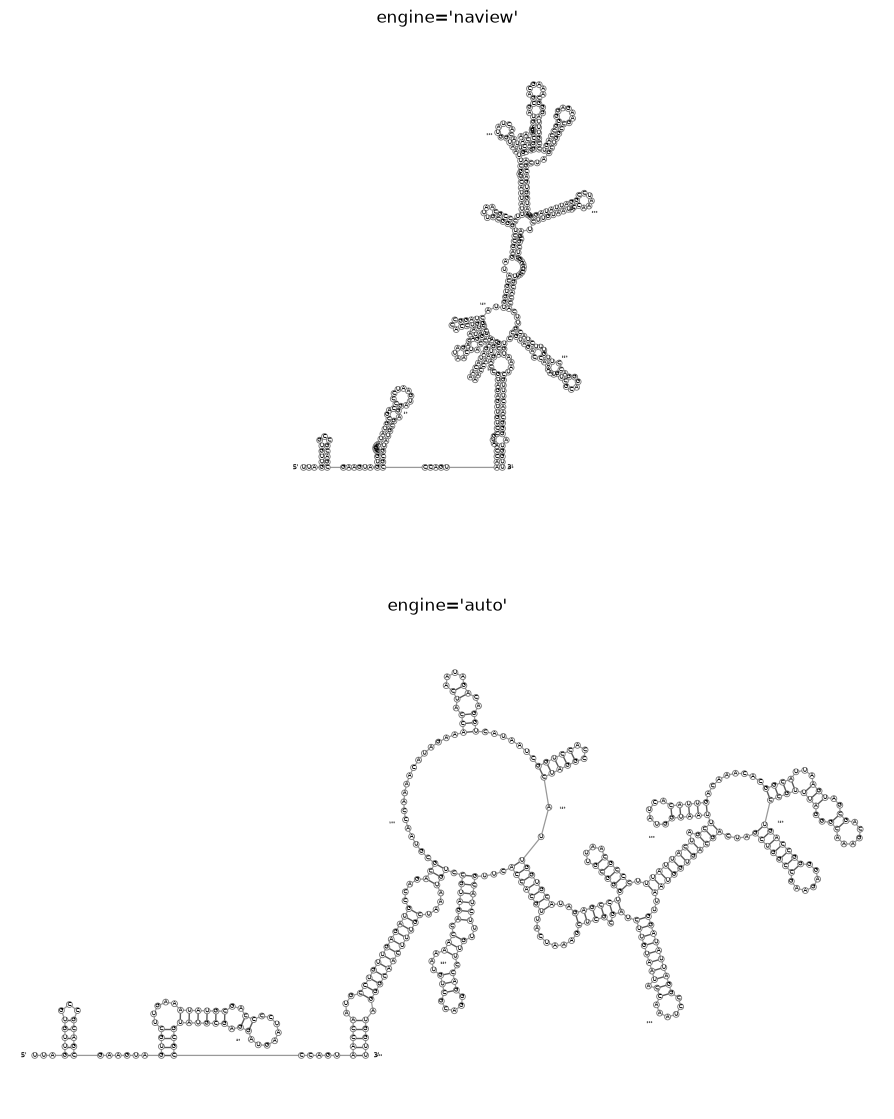

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(18, 14))
for ax, engine in zip(axes, ("naview", "auto")):
    rp.draw_structure(ax, big, big_db, engine=engine, letter_size=4, node_size=18, number_every=50)
    ax.set_title(f"engine={engine!r}")
plt.show()

## 7. Wild type vs mutant

Compute coordinates once per structure, and pass the same `highlight` to both panels.

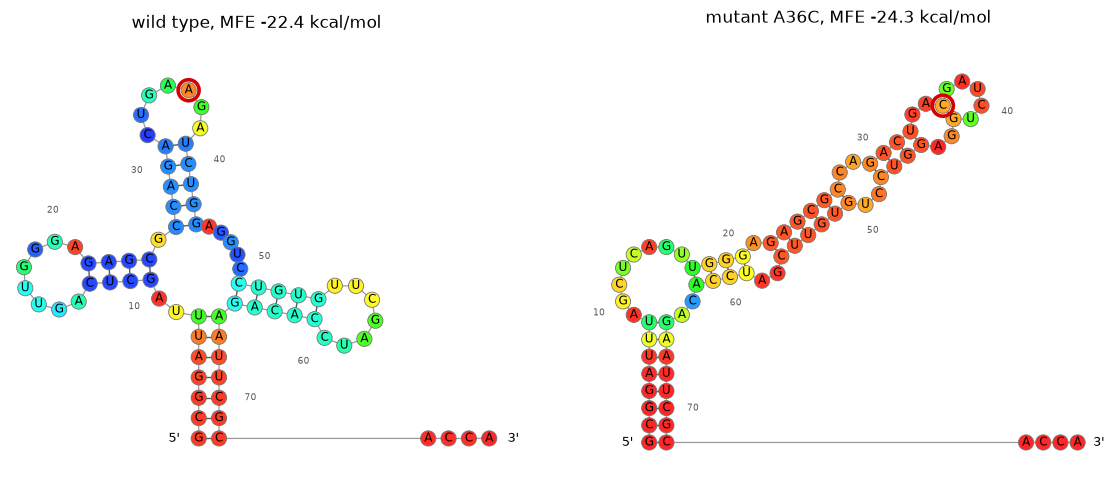

In [9]:
pos = 35
mut = TRNA[:pos] + "C" + TRNA[pos + 1 :]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, s) in zip(axes, (("wild type", TRNA), ("mutant A36C", mut))):
    d, e = RNA.fold(s)
    rp.draw_structure(
        ax, s, d, node_colors=rp.probability_colors(rp.pairing_probability(s, d)), highlight=[pos]
    )
    ax.set_title(f"{name}, MFE {e:.1f} kcal/mol")
plt.show()